<a href="https://colab.research.google.com/github/egypt81511/Hotel-Booking-Cancellation-Predict/blob/main/Hotel_Booking_Cancellation_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Hotel Reservations.csv")

df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [2]:

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (36275, 19)

Column names:
['Booking_ID', 'no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests', 'booking_status']


In [3]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

Duplicate rows: 0


booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64


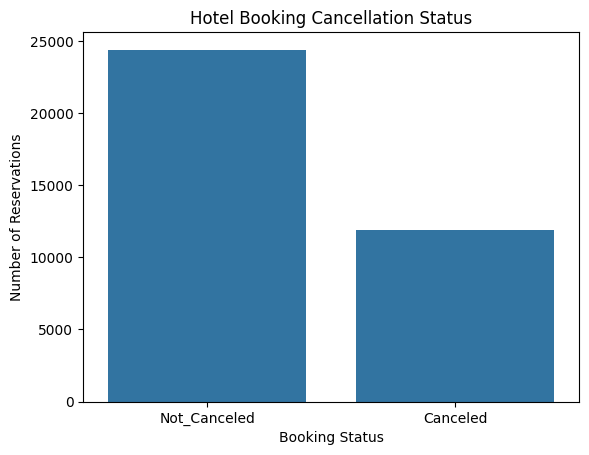


Cancellation percentages:
booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


In [4]:
print(df["booking_status"].value_counts())

sns.countplot(data=df, x="booking_status")
plt.title("Hotel Booking Cancellation Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Reservations")
plt.show()

print("\nCancellation percentages:")
print(df["booking_status"].value_counts(normalize=True) * 100)

booking_status
Canceled        139.215482
Not_Canceled     58.927224
Name: lead_time, dtype: float64


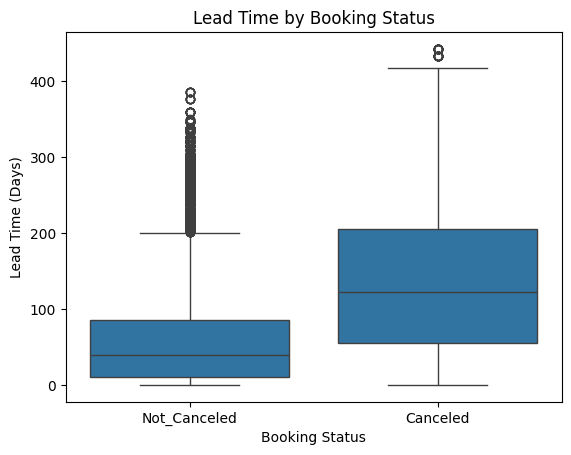

In [5]:

# Average lead time by booking status
print(df.groupby("booking_status")["lead_time"].mean())

# Compare lead time for canceled and non-canceled bookings
sns.boxplot(data=df, x="booking_status", y="lead_time")
plt.title("Lead Time by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (Days)")
plt.show()

booking_status
Canceled        110.589966
Not_Canceled     99.931412
Name: avg_price_per_room, dtype: float64


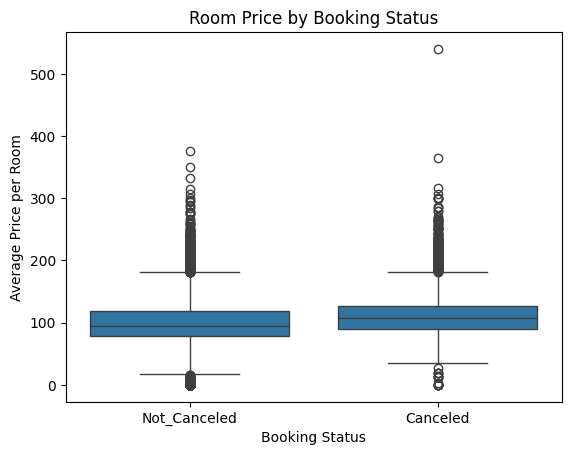

In [6]:

# Average room price by booking status
print(df.groupby("booking_status")["avg_price_per_room"].mean())

# Compare room prices
sns.boxplot(data=df, x="booking_status", y="avg_price_per_room")
plt.title("Room Price by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Average Price per Room")
plt.show()

booking_status
Canceled        0.334623
Not_Canceled    0.758549
Name: no_of_special_requests, dtype: float64


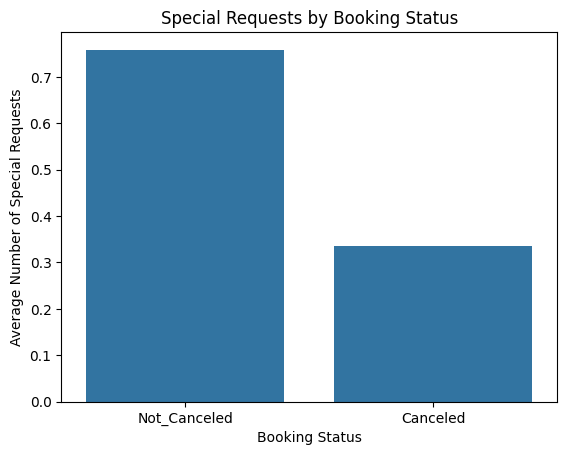

In [7]:

# Average number of special requests by booking status
print(df.groupby("booking_status")["no_of_special_requests"].mean())

# Compare special requests by booking status
sns.barplot(data=df, x="booking_status",
            y="no_of_special_requests",
            errorbar=None)

plt.title("Special Requests by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Average Number of Special Requests")
plt.show()

In [8]:
print(df.dtypes)

Booking_ID                               object
no_of_adults                              int64
no_of_children                            int64
no_of_weekend_nights                      int64
no_of_week_nights                         int64
type_of_meal_plan                        object
required_car_parking_space                int64
room_type_reserved                       object
lead_time                                 int64
arrival_year                              int64
arrival_month                             int64
arrival_date                              int64
market_segment_type                      object
repeated_guest                            int64
no_of_previous_cancellations              int64
no_of_previous_bookings_not_canceled      int64
avg_price_per_room                      float64
no_of_special_requests                    int64
booking_status                           object
dtype: object


In [9]:
df = df.drop(columns=["Booking_ID"])

print(df.shape)

(36275, 18)


In [10]:
df["booking_status"] = df["booking_status"].map({
    "Not_Canceled": 0,
    "Canceled": 1
})

print(df["booking_status"].value_counts())

booking_status
0    24390
1    11885
Name: count, dtype: int64


In [11]:
print(df["type_of_meal_plan"].unique())

print(df["room_type_reserved"].unique())

print(df["market_segment_type"].unique())

['Meal Plan 1' 'Not Selected' 'Meal Plan 2' 'Meal Plan 3']
['Room_Type 1' 'Room_Type 4' 'Room_Type 2' 'Room_Type 6' 'Room_Type 5'
 'Room_Type 7' 'Room_Type 3']
['Offline' 'Online' 'Corporate' 'Aviation' 'Complementary']


In [12]:
X = df.drop(columns=["booking_status"])
y = df["booking_status"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (36275, 17)
Target: (36275,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (29020, 17)
Testing features: (7255, 17)
Training target: (29020,)
Testing target: (7255,)


In [14]:
# Create two new features for the training data
X_train["total_nights"] = (
    X_train["no_of_weekend_nights"] +
    X_train["no_of_week_nights"]
)

X_train["total_guests"] = (
    X_train["no_of_adults"] +
    X_train["no_of_children"]
)

# Create the same features for the testing data
X_test["total_nights"] = (
    X_test["no_of_weekend_nights"] +
    X_test["no_of_week_nights"]
)

X_test["total_guests"] = (
    X_test["no_of_adults"] +
    X_test["no_of_children"]
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (29020, 19)
Testing features: (7255, 19)


In [15]:
# Identify categorical columns
categorical_cols = [
    "type_of_meal_plan",
    "room_type_reserved",
    "market_segment_type"
]

# Convert categorical columns into numbers
X_train = pd.get_dummies(X_train, columns=categorical_cols)
X_test = pd.get_dummies(X_test, columns=categorical_cols)

# Make sure training and testing have the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=False)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (29020, 32)
Testing features: (7255, 32)


In [16]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale the training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale the testing data
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (29020, 32)
Scaled testing data: (7255, 32)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict cancellations using the testing data
lr_predictions = lr_model.predict(X_test_scaled)

# Evaluate the model
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 0.8143349414197105

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      4878
           1       0.75      0.64      0.69      2377

    accuracy                           0.81      7255
   macro avg       0.80      0.77      0.78      7255
weighted avg       0.81      0.81      0.81      7255



In [18]:
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Predict cancellations
knn_predictions = knn_model.predict(X_test_scaled)

# Evaluate the model
print("KNN Accuracy:",
      accuracy_score(y_test, knn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions))

KNN Accuracy: 0.8516884906960717

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4878
           1       0.79      0.74      0.77      2377

    accuracy                           0.85      7255
   macro avg       0.83      0.82      0.83      7255
weighted avg       0.85      0.85      0.85      7255



In [19]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict cancellations
dt_predictions = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 0.8747070985527222

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      4878
           1       0.80      0.82      0.81      2377

    accuracy                           0.87      7255
   macro avg       0.86      0.86      0.86      7255
weighted avg       0.88      0.87      0.87      7255



In [20]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict cancellations
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.9035148173673329

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      4878
           1       0.89      0.81      0.85      2377

    accuracy                           0.90      7255
   macro avg       0.90      0.88      0.89      7255
weighted avg       0.90      0.90      0.90      7255



In [21]:
from xgboost import XGBClassifier

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train, y_train)

# Predict cancellations
xgb_predictions = xgb_model.predict(X_test)

# Evaluate the model
print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

XGBoost Accuracy: 0.8991040661612681

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.93      4878
           1       0.87      0.81      0.84      2377

    accuracy                           0.90      7255
   macro avg       0.89      0.88      0.88      7255
weighted avg       0.90      0.90      0.90      7255



In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": lr_predictions,
    "KNN": knn_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8143     0.7534  0.6441    0.6945
1                  KNN    0.8517     0.7916  0.7430    0.7665
2        Decision Tree    0.8747     0.8048  0.8153    0.8100
3        Random Forest    0.9035     0.8859  0.8098    0.8462
4              XGBoost    0.8991     0.8710  0.8124    0.8407


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

# Settings to experiment with
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Tune Random Forest using training data only
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=12,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best Parameters:", rf_search.best_params_)
print("Best Cross-Validation F1:", rf_search.best_score_)

Best Parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Best Cross-Validation F1: 0.8300011886302348


In [24]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Get the best tuned Random Forest model
rf_tuned = rf_search.best_estimator_

# Make predictions on the test data
rf_tuned_predictions = rf_tuned.predict(X_test)

# Evaluate the tuned model
print("Tuned Random Forest Results")
print("Accuracy:", round(accuracy_score(y_test, rf_tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_tuned_predictions), 4))
print("Recall:", round(recall_score(y_test, rf_tuned_predictions), 4))
print("F1-Score:", round(f1_score(y_test, rf_tuned_predictions), 4))

Tuned Random Forest Results
Accuracy: 0.9041
Precision: 0.8864
Recall: 0.8111
F1-Score: 0.8471


In [25]:

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# Settings to experiment with
xgb_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0]
}

# Tune XGBoost using training data
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ),
    param_distributions=xgb_params,
    n_iter=12,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best Cross-Validation F1:", xgb_search.best_score_)

Best Parameters: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.1}
Best Cross-Validation F1: 0.8295113897857381


In [26]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Get the best tuned XGBoost model
xgb_tuned = xgb_search.best_estimator_

# Make predictions using the test data
xgb_tuned_predictions = xgb_tuned.predict(X_test)

# Evaluate the tuned model
print("Tuned XGBoost Results")
print("Accuracy:", round(accuracy_score(y_test, xgb_tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, xgb_tuned_predictions), 4))
print("Recall:", round(recall_score(y_test, xgb_tuned_predictions), 4))
print("F1-Score:", round(f1_score(y_test, xgb_tuned_predictions), 4))

Tuned XGBoost Results
Accuracy: 0.9041
Precision: 0.8751
Recall: 0.825
F1-Score: 0.8493


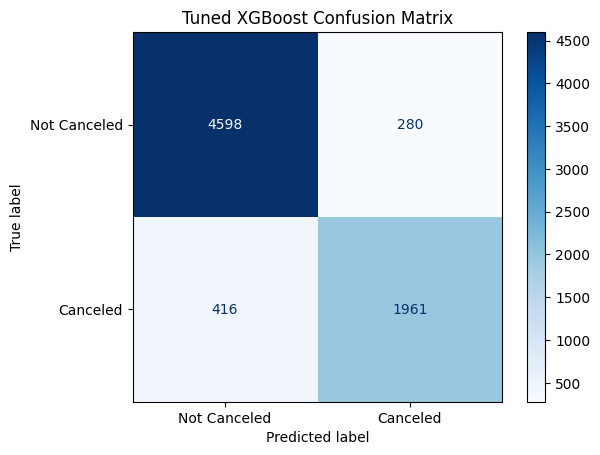

In [27]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrix for tuned XGBoost
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_tuned_predictions,
    display_labels=["Not Canceled", "Canceled"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned XGBoost Confusion Matrix")
plt.show()

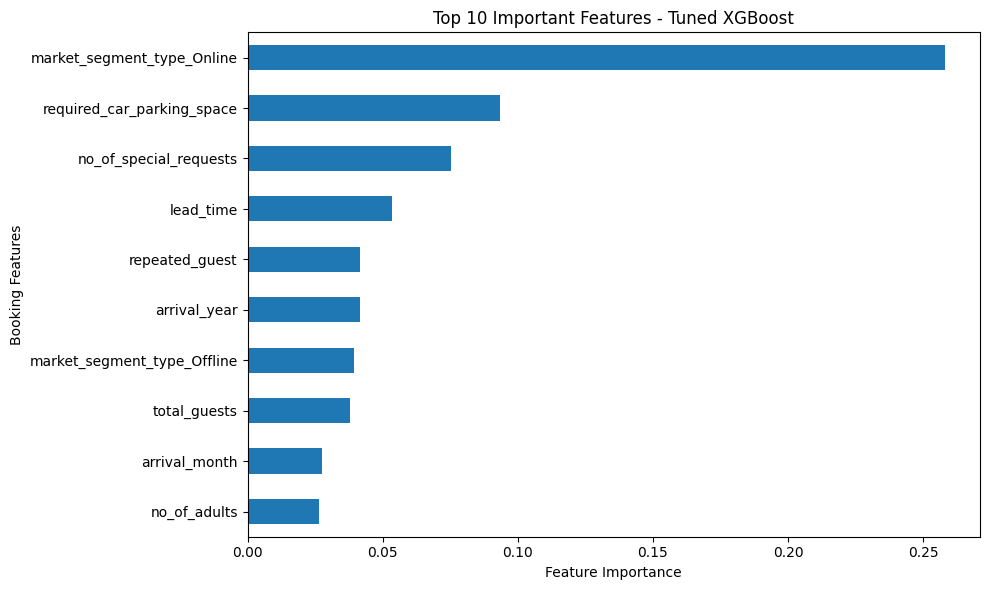

In [28]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from tuned XGBoost
importance = pd.Series(
    xgb_tuned.feature_importances_,
    index=X_train.columns
)

# Select the 10 most important features
top_features = importance.sort_values(
    ascending=False
).head(10)

# Create feature importance chart
plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind="barh")

plt.title("Top 10 Important Features - Tuned XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Booking Features")
plt.tight_layout()
plt.show()

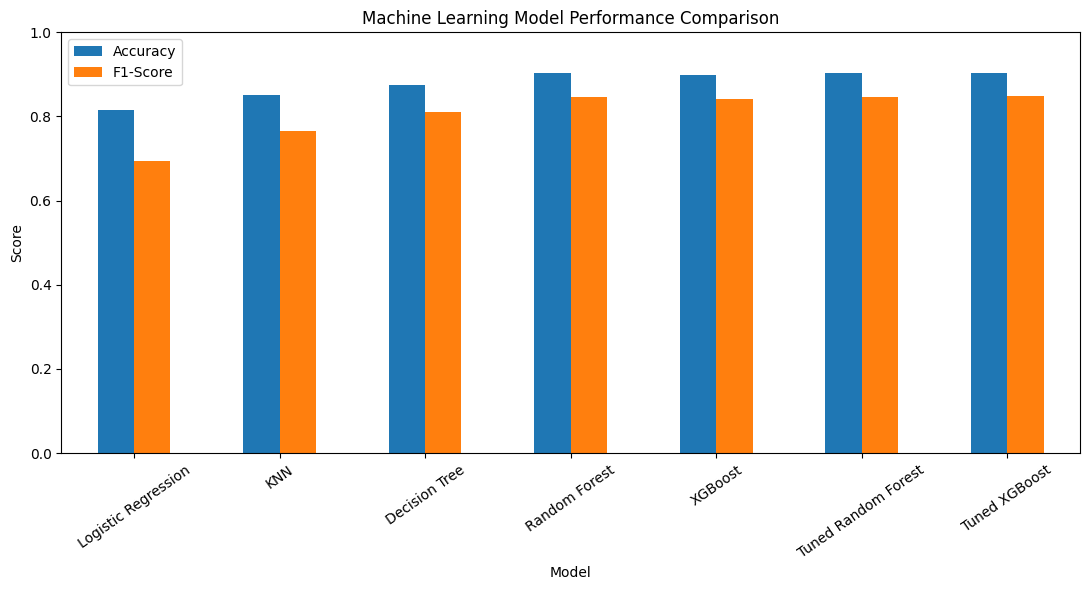

In [29]:

import pandas as pd
import matplotlib.pyplot as plt

# Compare original and tuned models
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        0.8143, 0.8517, 0.8747,
        0.9035, 0.8991, 0.9041, 0.9041
    ],
    "F1-Score": [
        0.6945, 0.7665, 0.8100,
        0.8462, 0.8407, 0.8471, 0.8493
    ]
})

# Plot accuracy and F1-score
final_results.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6),
    rot=35
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()